In [1]:
from astropy.io import fits
from astropy.table import Table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
file_path = "/Users/khushi/Downloads/erass1cl_primary_v3.2.fits"

columns = [
    "NAME", "BEST_Z", "BEST_ZERR",
    "KT", "KT_L", "KT_H",
    "M500", "M500_L", "M500_H",
    "Lbol500", "Lbol500_L", "Lbol500_H"
]

with fits.open(file_path) as hdul:
    astro_table = Table(hdul[1].data)[columns]

df = astro_table.to_pandas()

print("Original number of objects:", len(df))
display(df.head())

Original number of objects: 12247


,NAME,BEST_Z,BEST_ZERR,KT,KT_L,KT_H,M500,M500_L,M500_H,Lbol500,Lbol500_L,Lbol500_H
0,1eRASS J000005.2-383729,0.3153,0.0079,1.90,1.37,3.53,36.07,29.45,44.96,253.286,196.126,349.587
1,1eRASS J000021.4-824954,0.0891,0.0002,-1.00,3.82,-1.00,16.99,15.65,18.85,76.492,53.559,123.554
2,1eRASS J000031.0-500903,0.0681,0.0002,1.79,1.22,8.61,3.63,2.30,4.81,6.450,3.926,12.952
3,1eRASS J000031.8-630131,0.2448,0.0058,-1.00,1.54,-1.00,22.04,17.89,28.39,134.905,90.752,243.718
4,1eRASS J000045.3-462341,0.0925,0.0004,0.96,0.48,7.53,3.78,2.63,4.86,7.076,4.163,12.315


In [3]:
valid = (
    (df["BEST_Z"] > 0) &
    (df["KT"] > 0) &
    (df["M500"] > 0) &
    (df["Lbol500"] > 0)
)

df_clean = df[valid].copy()

print("Original sample:", len(df))
print("Clean sample:", len(df_clean))
print("Removed:", len(df) - len(df_clean))

display(df_clean.head(10))

Original sample: 12247
Clean sample: 3388
Removed: 8859


,NAME,BEST_Z,BEST_ZERR,KT,KT_L,KT_H,M500,M500_L,M500_H,Lbol500,Lbol500_L,Lbol500_H
0,1eRASS J000005.2-383729,0.3153,0.0079,1.90,1.37,3.53,36.07,29.45,44.96,253.286,196.126,349.587
2,1eRASS J000031.0-500903,0.0681,0.0002,1.79,1.22,8.61,3.63,2.30,4.81,6.450,3.926,12.952
4,1eRASS J000045.3-462341,0.0925,0.0004,0.96,0.48,7.53,3.78,2.63,4.86,7.076,4.163,12.315
5,1eRASS J000056.7-682010,0.2415,0.0073,1.17,0.83,6.07,14.25,11.27,17.42,60.897,43.725,94.708
19,1eRASS J000220.3-435849,0.0397,0.0003,1.08,0.83,3.05,9.03,8.00,10.30,14.771,12.324,19.893
22,1eRASS J000240.5-344030,0.1134,0.0007,1.24,0.86,2.33,13.46,11.04,16.37,35.078,26.488,48.338
24,1eRASS J000313.1-355607,0.0500,0.0004,1.94,1.55,2.05,22.77,21.19,24.88,62.355,58.380,67.151
30,1eRASS J000416.3-642519,0.1178,0.0004,1.40,1.28,2.36,24.09,21.66,26.24,70.557,61.546,81.964
33,1eRASS J000439.7-770812,0.3306,0.0085,2.06,1.28,6.84,25.41,19.86,34.88,183.483,137.049,281.172
37,1eRASS J000508.7-614657,0.0951,0.0004,1.18,1.06,1.44,14.91,12.94,17.19,31.904,25.732,38.126


In [4]:
df_clean["log_KT"] = np.log10(df_clean["KT"])
df_clean["log_M500"] = np.log10(df_clean["M500"])
df_clean["log_Lbol500"] = np.log10(df_clean["Lbol500"])

### FIRST FITTING PASS

In [5]:
# Mass-temperature fit
slope_MT, intercept_MT = np.polyfit(df_clean["log_KT"],df_clean["log_M500"],1)

coeff_MT, cov_MT = np.polyfit(df_clean["log_KT"],df_clean["log_M500"],1,cov=True)

slope_error_MT = np.sqrt(cov_MT[0, 0])


# Luminosity-temperature fit
slope_LT, intercept_LT = np.polyfit(df_clean["log_KT"],df_clean["log_Lbol500"],1)

coeff_LT, cov_LT = np.polyfit(df_clean["log_KT"],df_clean["log_Lbol500"],1,cov=True)

slope_error_LT = np.sqrt(cov_LT[0, 0])


# Print results
print("FIRST FITTING PASS: UNWEIGHTED")

print(f"Mass-Temperature slope: {slope_MT:.3f} ± {slope_error_MT:.3f}")
print(f"Mass-Temperature intercept: {intercept_MT:.3f}")
print(f"Number of objects used: {len(df_clean)}")

print()

print(f"Luminosity-Temperature slope: {slope_LT:.3f} ± {slope_error_LT:.3f}")
print(f"Luminosity-Temperature intercept: {intercept_LT:.3f}")
print(f"Number of objects used: {len(df_clean)}")

FIRST FITTING PASS: UNWEIGHTED
Mass-Temperature slope: 0.893 ± 0.020
Mass-Temperature intercept: 1.053
Number of objects used: 3388

Luminosity-Temperature slope: 1.549 ± 0.038
Luminosity-Temperature intercept: 1.591
Number of objects used: 3388


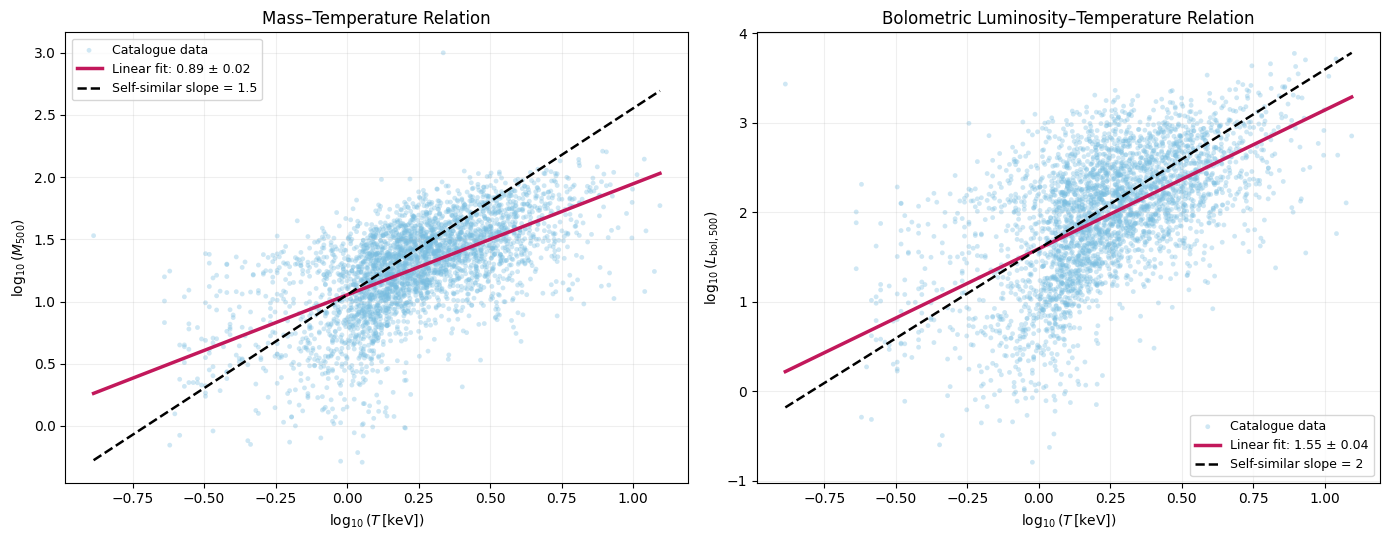

In [6]:
data_color = "#78BDE0"
fit_color = "#C2185B"

x = np.linspace(df_clean["log_KT"].min(),df_clean["log_KT"].max(),200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))


# Mass-temperature plot
axes[0].scatter(df_clean["log_KT"],df_clean["log_M500"],s=12,alpha=0.35,color=data_color,edgecolors="none",label="Catalogue data")

axes[0].plot(x,slope_MT*x + intercept_MT,color=fit_color,linewidth=2.5,label=f"Linear fit: {slope_MT:.2f} ± {slope_error_MT:.2f}")

axes[0].plot(x,1.5*x + intercept_MT,color="black",linestyle="--",linewidth=1.8,label="Self-similar slope = 1.5")

axes[0].set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
axes[0].set_ylabel(r"$\log_{10}(M_{500})$")
axes[0].set_title("Mass–Temperature Relation")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2)


# Luminosity-temperature plot
axes[1].scatter(df_clean["log_KT"],df_clean["log_Lbol500"],s=12,alpha=0.35,color=data_color,edgecolors="none",label="Catalogue data")

axes[1].plot(x,slope_LT*x + intercept_LT,color=fit_color,linewidth=2.5,label=f"Linear fit: {slope_LT:.2f} ± {slope_error_LT:.2f}")

axes[1].plot(x,2*x + intercept_LT,color="black",linestyle="--",linewidth=1.8,label="Self-similar slope = 2")

axes[1].set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
axes[1].set_ylabel(r"$\log_{10}(L_{\mathrm{bol},500})$")
axes[1].set_title("Bolometric Luminosity–Temperature Relation")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### SECOND FITTING PASS WITH UNCERTAINTIES (MASS + LUMINOSITY)

In [7]:
# Calculate the upper and lower uncertainties
df_clean["KT_err_low"] = df_clean["KT"] - df_clean["KT_L"]
df_clean["KT_err_high"] = df_clean["KT_H"] - df_clean["KT"]

df_clean["M500_err_low"] = df_clean["M500"] - df_clean["M500_L"]
df_clean["M500_err_high"] = df_clean["M500_H"] - df_clean["M500"]

df_clean["Lbol500_err_low"] = df_clean["Lbol500"] - df_clean["Lbol500_L"]
df_clean["Lbol500_err_high"] = df_clean["Lbol500_H"] - df_clean["Lbol500"]


# Convert the uncertainties to logarithmic space
for value, low, high in [
    ("KT", "KT_L", "KT_H"),
    ("M500", "M500_L", "M500_H"),
    ("Lbol500", "Lbol500_L", "Lbol500_H")]:

    df_clean[f"log_{value}_err_low"] = (
        np.log10(df_clean[value]) - np.log10(df_clean[low])
 )

    df_clean[f"log_{value}_err_high"] = (
        np.log10(df_clean[high]) - np.log10(df_clean[value])
    )

display(df_clean.head())

,NAME,BEST_Z,BEST_ZERR,KT,KT_L,KT_H,M500,M500_L,M500_H,Lbol500,...,M500_err_low,M500_err_high,Lbol500_err_low,Lbol500_err_high,log_KT_err_low,log_KT_err_high,log_M500_err_low,log_M500_err_high,log_Lbol500_err_low,log_Lbol500_err_high
0,1eRASS J000005.2-383729,0.3153,0.0079,1.90,1.37,3.53,36.07,29.45,44.96,253.286,...,6.62,8.89,57.160,96.301,0.142033,0.269021,0.088061,0.095680,0.111076,0.139944
2,1eRASS J000031.0-500903,0.0681,0.0002,1.79,1.22,8.61,3.63,2.30,4.81,6.450,...,1.33,1.18,2.524,6.502,0.166493,0.682150,0.198179,0.122238,0.215609,0.302777
4,1eRASS J000045.3-462341,0.0925,0.0004,0.96,0.48,7.53,3.78,2.63,4.86,7.076,...,1.15,1.08,2.913,5.239,0.301030,0.894524,0.157536,0.109144,0.230381,0.240647
5,1eRASS J000056.7-682010,0.2415,0.0073,1.17,0.83,6.07,14.25,11.27,17.42,60.897,...,2.98,3.17,17.172,33.811,0.149108,0.715003,0.101891,0.087233,0.143866,0.191791
19,1eRASS J000220.3-435849,0.0397,0.0003,1.08,0.83,3.05,9.03,8.00,10.30,14.771,...,1.03,1.27,2.447,5.122,0.114346,0.450876,0.052598,0.057149,0.078658,0.129290


In [8]:
# Check that the data and uncertainties are valid
def valid_fit_data(x, y, xerr_low, xerr_high, yerr_low, yerr_high):

    mask = (
        np.isfinite(x) &
        np.isfinite(y) &
        np.isfinite(xerr_low) &
        np.isfinite(xerr_high) &
        np.isfinite(yerr_low) &
        np.isfinite(yerr_high) &
        (xerr_low >= 0) &
        (xerr_high >= 0) &
        (yerr_low > 0) &
        (yerr_high > 0)
    )

    return mask


# Mass-temperature data
mask_MT = valid_fit_data(
    df_clean["log_KT"].to_numpy(),
    df_clean["log_M500"].to_numpy(),
    df_clean["log_KT_err_low"].to_numpy(),
    df_clean["log_KT_err_high"].to_numpy(),
    df_clean["log_M500_err_low"].to_numpy(),
    df_clean["log_M500_err_high"].to_numpy()
)

x_MT = df_clean.loc[mask_MT, "log_KT"].to_numpy()
y_MT = df_clean.loc[mask_MT, "log_M500"].to_numpy()

err_MT = (df_clean.loc[mask_MT, "log_M500_err_low"].to_numpy()+ df_clean.loc[mask_MT, "log_M500_err_high"].to_numpy()) / 2


# Luminosity-temperature data
mask_LT = valid_fit_data(
    df_clean["log_KT"].to_numpy(),
    df_clean["log_Lbol500"].to_numpy(),
    df_clean["log_KT_err_low"].to_numpy(),
    df_clean["log_KT_err_high"].to_numpy(),
    df_clean["log_Lbol500_err_low"].to_numpy(),
    df_clean["log_Lbol500_err_high"].to_numpy()
)

x_LT = df_clean.loc[mask_LT, "log_KT"].to_numpy()
y_LT = df_clean.loc[mask_LT, "log_Lbol500"].to_numpy()

err_LT = (df_clean.loc[mask_LT, "log_Lbol500_err_low"].to_numpy()+ df_clean.loc[mask_LT, "log_Lbol500_err_high"].to_numpy()) / 2


# Weighted mass-temperature fit
coeff_MT, cov_MT = np.polyfit(x_MT, y_MT, 1,w=1/err_MT,cov=True)

slope_MT = coeff_MT[0]
intercept_MT = coeff_MT[1]
slope_error_MT = np.sqrt(cov_MT[0, 0])


# Weighted luminosity-temperature fit
coeff_LT, cov_LT = np.polyfit(x_LT, y_LT, 1,w=1/err_LT,cov=True)

slope_LT = coeff_LT[0]
intercept_LT = coeff_LT[1]
slope_error_LT = np.sqrt(cov_LT[0, 0])


# Print results
print("SECOND FITTING PASS: WEIGHTED FITS")

print(f"Mass-Temperature slope: {slope_MT:.3f} ± {slope_error_MT:.3f}")
print(f"Mass-Temperature intercept: {intercept_MT:.3f}")
print(f"Number of objects used: {len(x_MT)}")

print()

print(f"Luminosity-Temperature slope: {slope_LT:.3f} ± {slope_error_LT:.3f}")
print(f"Luminosity-Temperature intercept: {intercept_LT:.3f}")
print(f"Number of objects used: {len(x_LT)}")

SECOND FITTING PASS: WEIGHTED FITS
Mass-Temperature slope: 0.955 ± 0.017
Mass-Temperature intercept: 1.096
Number of objects used: 3387

Luminosity-Temperature slope: 2.034 ± 0.035
Luminosity-Temperature intercept: 1.398
Number of objects used: 3388


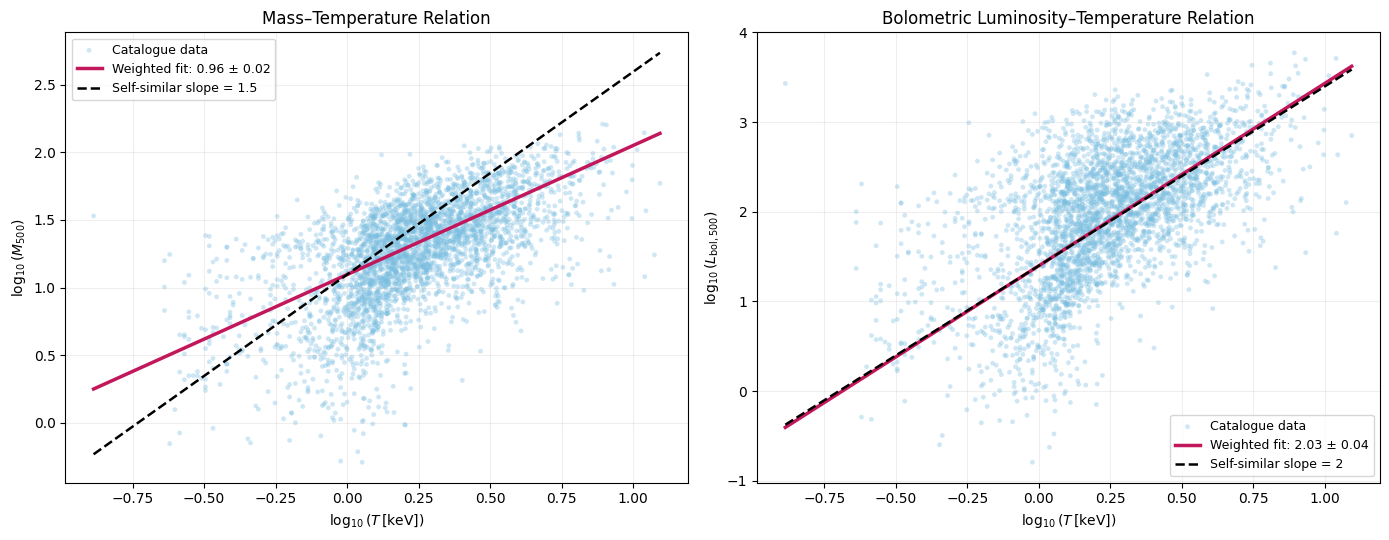

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x_line_MT = np.linspace(x_MT.min(), x_MT.max(), 200)
x_line_LT = np.linspace(x_LT.min(), x_LT.max(), 200)


# Mass-temperature plot
axes[0].scatter(x_MT, y_MT,s=12, alpha=0.35,color=data_color, edgecolors="none",label="Catalogue data")

axes[0].plot(x_line_MT,slope_MT*x_line_MT + intercept_MT,color=fit_color,linewidth=2.5,label=f"Weighted fit: {slope_MT:.2f} ± {slope_error_MT:.2f}")

axes[0].plot(x_line_MT,1.5*x_line_MT + intercept_MT,color="black",linestyle="--",linewidth=1.8,label="Self-similar slope = 1.5")

axes[0].set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
axes[0].set_ylabel(r"$\log_{10}(M_{500})$")
axes[0].set_title("Mass–Temperature Relation")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2)


# Luminosity-temperature plot
axes[1].scatter(x_LT, y_LT,s=12, alpha=0.35,color=data_color, edgecolors="none",label="Catalogue data")

axes[1].plot(x_line_LT,slope_LT*x_line_LT + intercept_LT,color=fit_color,linewidth=2.5,label=f"Weighted fit: {slope_LT:.2f} ± {slope_error_LT:.2f}")

axes[1].plot(x_line_LT,2*x_line_LT + intercept_LT,color="black",linestyle="--",linewidth=1.8,label="Self-similar slope = 2")

axes[1].set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
axes[1].set_ylabel(r"$\log_{10}(L_{\mathrm{bol},500})$")
axes[1].set_title("Bolometric Luminosity–Temperature Relation")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### THIRD FITTING PASS — ACCOUNTING FOR UNCERTAINTIES IN BOTH VARIABLES

In [10]:
def fit_with_xy_errors(x, y, xerr, yerr):

    # Start with a fit using the y uncertainties
    slope, intercept = np.polyfit(x, y, 1, w=1/yerr)

    # Keep updating the fit until the slope converges
    for i in range(100):

        err_eff = np.sqrt(yerr**2 + (slope*xerr)**2)

        coeff, cov = np.polyfit(x, y, 1,w=1/err_eff,cov=True)

        new_slope = coeff[0]
        new_intercept = coeff[1]

        if abs(new_slope - slope) < 1e-8:
            slope = new_slope
            intercept = new_intercept
            break

        slope = new_slope
        intercept = new_intercept

    # Calculate the final slope uncertainty
    err_eff = np.sqrt(yerr**2 + (slope*xerr)**2)

    coeff, cov = np.polyfit(x, y, 1,w=1/err_eff,cov=True)

    slope = coeff[0]
    intercept = coeff[1]
    slope_error = np.sqrt(cov[0, 0])

    return slope, intercept, slope_error

In [11]:
# Calculate average uncertainties in logarithmic space
xerr_MT = (df_clean.loc[mask_MT, "log_KT_err_low"].to_numpy()+ df_clean.loc[mask_MT, "log_KT_err_high"].to_numpy()) / 2

yerr_MT = (df_clean.loc[mask_MT, "log_M500_err_low"].to_numpy()+ df_clean.loc[mask_MT, "log_M500_err_high"].to_numpy()) / 2

xerr_LT = (df_clean.loc[mask_LT, "log_KT_err_low"].to_numpy()+ df_clean.loc[mask_LT, "log_KT_err_high"].to_numpy()) / 2

yerr_LT = (df_clean.loc[mask_LT, "log_Lbol500_err_low"].to_numpy()+ df_clean.loc[mask_LT, "log_Lbol500_err_high"].to_numpy()) / 2


# Mass-temperature fit
slope_MT, intercept_MT, slope_error_MT = fit_with_xy_errors(x_MT, y_MT, xerr_MT, yerr_MT)


# Luminosity-temperature fit
slope_LT, intercept_LT, slope_error_LT = fit_with_xy_errors(x_LT, y_LT, xerr_LT, yerr_LT)


# Print results
print("THIRD FITTING PASS: EFFECTIVE-VARIANCE FITS")

print(f"Mass-Temperature slope: {slope_MT:.3f} ± {slope_error_MT:.3f}")
print(f"Mass-Temperature intercept: {intercept_MT:.3f}")
print(f"Number of objects used: {len(x_MT)}")

print()

print(f"Luminosity-Temperature slope: {slope_LT:.3f} ± {slope_error_LT:.3f}")
print(f"Luminosity-Temperature intercept: {intercept_LT:.3f}")
print(f"Number of objects used: {len(x_LT)}")

THIRD FITTING PASS: EFFECTIVE-VARIANCE FITS
Mass-Temperature slope: 1.173 ± 0.020
Mass-Temperature intercept: 0.996
Number of objects used: 3387

Luminosity-Temperature slope: 2.271 ± 0.041
Luminosity-Temperature intercept: 1.194
Number of objects used: 3388


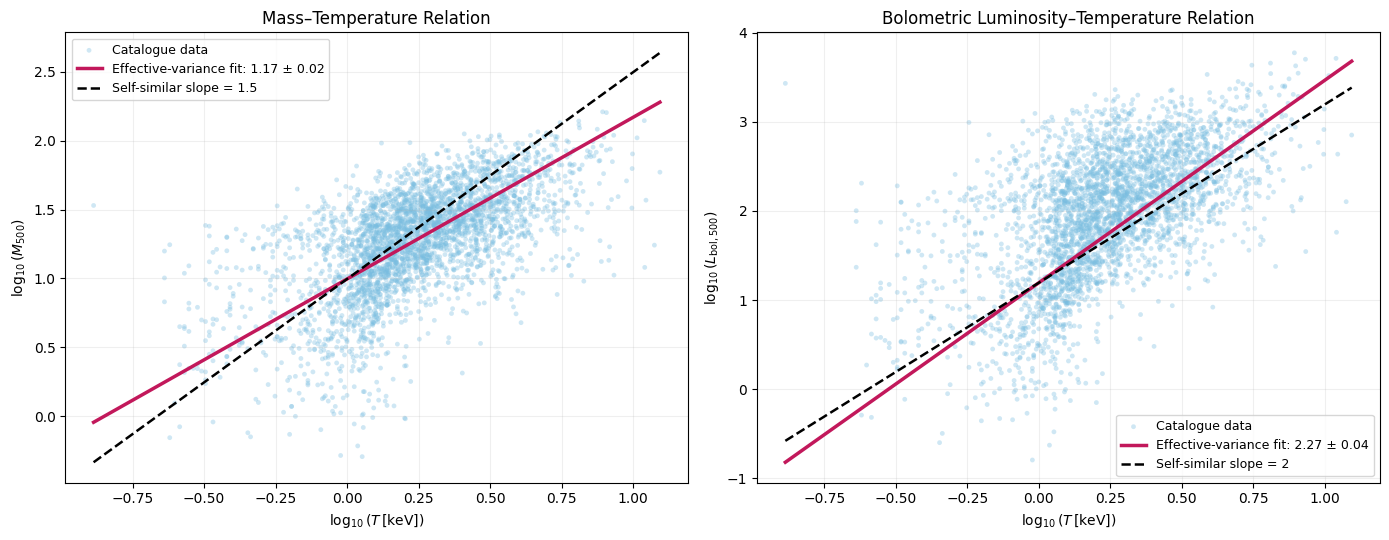

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x_line_MT = np.linspace(x_MT.min(), x_MT.max(), 200)
x_line_LT = np.linspace(x_LT.min(), x_LT.max(), 200)


# Mass-temperature plot
axes[0].scatter(x_MT, y_MT,s=12, alpha=0.35,color=data_color, edgecolors="none",label="Catalogue data")

axes[0].plot(x_line_MT,slope_MT*x_line_MT + intercept_MT,color=fit_color,linewidth=2.5,label=f"Effective-variance fit: {slope_MT:.2f} ± {slope_error_MT:.2f}")

axes[0].plot(x_line_MT,1.5*x_line_MT + intercept_MT,color="black",linestyle="--",linewidth=1.8,label="Self-similar slope = 1.5")

axes[0].set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
axes[0].set_ylabel(r"$\log_{10}(M_{500})$")
axes[0].set_title("Mass–Temperature Relation")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2)


# Luminosity-temperature plot
axes[1].scatter(x_LT, y_LT,s=12, alpha=0.35,color=data_color, edgecolors="none",label="Catalogue data")

axes[1].plot(x_line_LT,slope_LT*x_line_LT + intercept_LT,color=fit_color,linewidth=2.5,label=f"Effective-variance fit: {slope_LT:.2f} ± {slope_error_LT:.2f}")

axes[1].plot(x_line_LT,2*x_line_LT + intercept_LT,color="black",linestyle="--",linewidth=1.8,label="Self-similar slope = 2")

axes[1].set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
axes[1].set_ylabel(r"$\log_{10}(L_{\mathrm{bol},500})$")
axes[1].set_title("Bolometric Luminosity–Temperature Relation")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### TEMP DEPENDANCE

In [13]:
# Create separate dataframes for the two relations
df_mt_temp = df_clean.loc[mask_MT].copy()
df_lt_temp = df_clean.loc[mask_LT].copy()


# Calculate average uncertainties
df_mt_temp["xerr"] = (df_mt_temp["log_KT_err_low"] + df_mt_temp["log_KT_err_high"]) / 2
df_mt_temp["yerr"] = (df_mt_temp["log_M500_err_low"] + df_mt_temp["log_M500_err_high"]) / 2

df_lt_temp["xerr"] = (df_lt_temp["log_KT_err_low"] + df_lt_temp["log_KT_err_high"]) / 2
df_lt_temp["yerr"] = (df_lt_temp["log_Lbol500_err_low"] + df_lt_temp["log_Lbol500_err_high"]) / 2

In [14]:
labels = [
    "Low temperature",
    "Intermediate temperature",
    "High temperature"
]

df_mt_temp["temp_bin"], mt_edges = pd.qcut(df_mt_temp["KT"],q=3,labels=labels,retbins=True)

df_lt_temp["temp_bin"], lt_edges = pd.qcut(df_lt_temp["KT"],q=3,labels=labels,retbins=True)

print("Mass-temperature bin edges:", mt_edges)
print("Luminosity-temperature bin edges:", lt_edges)

Mass-temperature bin edges: [ 0.13  1.34  2.18 12.42]
Luminosity-temperature bin edges: [ 0.13  1.34  2.18 12.42]


In [15]:
mt_results = {}

print("MASS-TEMPERATURE RELATION")

for label in labels:

    subset = df_mt_temp[df_mt_temp["temp_bin"] == label]

    x = subset["log_KT"].to_numpy()
    y = subset["log_M500"].to_numpy()
    xerr = subset["xerr"].to_numpy()
    yerr = subset["yerr"].to_numpy()

    slope, intercept, slope_error = fit_with_xy_errors(x, y, xerr, yerr)

    mt_results[label] = (slope, intercept, slope_error)

    print(f"\n{label}")
    print(f"Mass-Temperature slope: {slope:.4f} ± {slope_error:.4f}")
    print(f"Mass-Temperature intercept: {intercept:.4f}")
    print(f"Number of objects used: {len(subset)}")

MASS-TEMPERATURE RELATION

Low temperature
Mass-Temperature slope: 0.9737 ± 0.0814
Mass-Temperature intercept: 0.9575
Number of objects used: 1133

Intermediate temperature
Mass-Temperature slope: 1.5581 ± 0.1163
Mass-Temperature intercept: 0.9944
Number of objects used: 1129

High temperature
Mass-Temperature slope: 0.7568 ± 0.0410
Mass-Temperature intercept: 1.2191
Number of objects used: 1125


In [16]:
lt_results = {}

print("LUMINOSITY-TEMPERATURE RELATION")

for label in labels:

    subset = df_lt_temp[df_lt_temp["temp_bin"] == label]

    x = subset["log_KT"].to_numpy()
    y = subset["log_Lbol500"].to_numpy()
    xerr = subset["xerr"].to_numpy()
    yerr = subset["yerr"].to_numpy()

    slope, intercept, slope_error = fit_with_xy_errors(x, y, xerr, yerr)

    lt_results[label] = (slope, intercept, slope_error)

    print(f"\n{label}")
    print(f"Luminosity-Temperature slope: {slope:.4f} ± {slope_error:.4f}")
    print(f"Luminosity-Temperature intercept: {intercept:.4f}")
    print(f"Number of objects used: {len(subset)}")

LUMINOSITY-TEMPERATURE RELATION

Low temperature
Luminosity-Temperature slope: 1.4304 ± 0.1747
Luminosity-Temperature intercept: 1.1804
Number of objects used: 1133

Intermediate temperature
Luminosity-Temperature slope: 0.8625 ± 0.1974
Luminosity-Temperature intercept: 1.6315
Number of objects used: 1130

High temperature
Luminosity-Temperature slope: 1.9115 ± 0.0773
Luminosity-Temperature intercept: 1.4314
Number of objects used: 1125


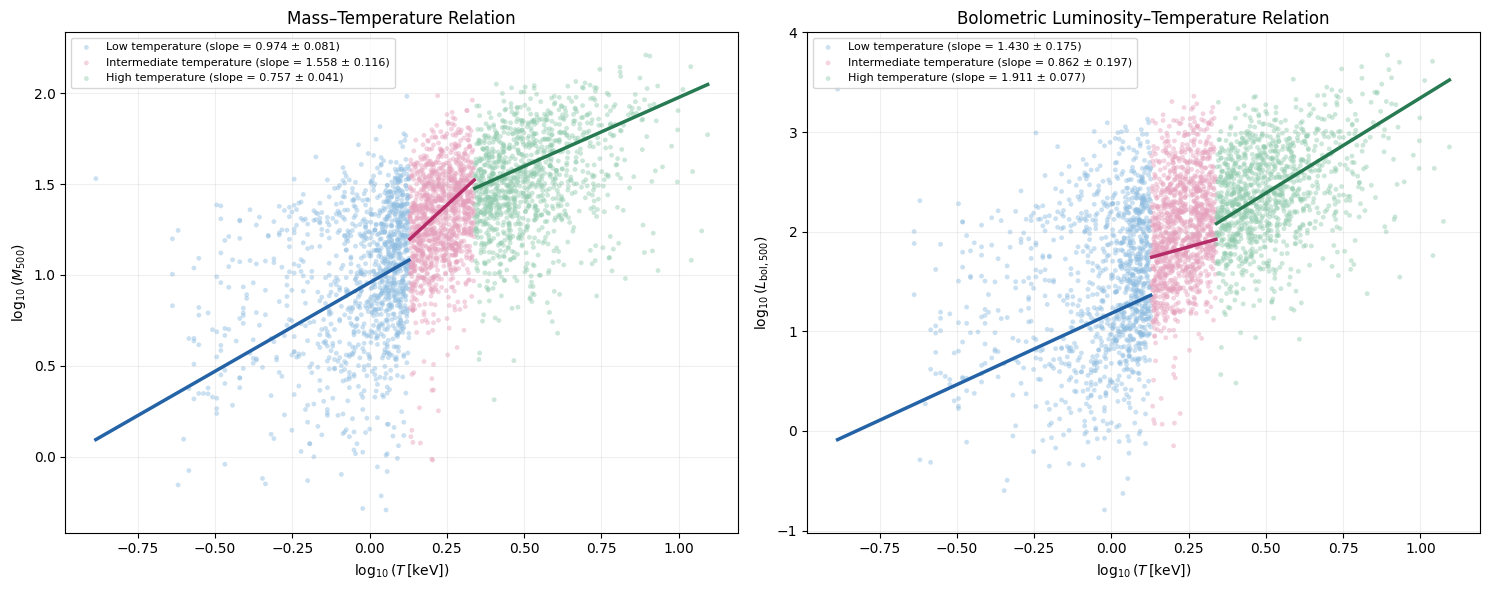

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

point_colors = {"Low temperature": "#8DBCE0","Intermediate temperature": "#E5A0BC","High temperature": "#91CBAE"}

line_colors = {"Low temperature": "#2463A6","Intermediate temperature": "#B52D68","High temperature": "#287A52"}


# Mass-temperature plot
ax = axes[0]

for label in labels:

    subset = df_mt_temp[df_mt_temp["temp_bin"] == label]

    x = subset["log_KT"]
    y = subset["log_M500"]

    slope, intercept, slope_error = mt_results[label]

    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = slope*x_fit + intercept

    ax.scatter(x, y,s=12,alpha=0.45,color=point_colors[label],edgecolors="none",label=f"{label} (slope = {slope:.3f} ± {slope_error:.3f})")

    ax.plot(x_fit, y_fit,color=line_colors[label],linewidth=2.5)

ax.set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
ax.set_ylabel(r"$\log_{10}(M_{500})$")
ax.set_title("Mass–Temperature Relation")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)


# Luminosity-temperature plot
ax = axes[1]

for label in labels:

    subset = df_lt_temp[df_lt_temp["temp_bin"] == label]

    x = subset["log_KT"]
    y = subset["log_Lbol500"]

    slope, intercept, slope_error = lt_results[label]

    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = slope*x_fit + intercept

    ax.scatter(x, y,s=12,alpha=0.45,color=point_colors[label],edgecolors="none",label=f"{label} (slope = {slope:.3f} ± {slope_error:.3f})")

    ax.plot(x_fit, y_fit,color=line_colors[label],linewidth=2.5)

ax.set_xlabel(r"$\log_{10}(T\,[\mathrm{keV}])$")
ax.set_ylabel(r"$\log_{10}(L_{\mathrm{bol},500})$")
ax.set_title("Bolometric Luminosity–Temperature Relation")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()